<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 5 · Multi-step forecasting</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

On a synthetic weekly harvest, one random forest predicting all 8 weeks at once beat eight separate forests on average error in all 8 test histories, fitted 7 times faster and drew smoother forecast paths, but it was the worst forest for next week. That one model is a **multi-output** model: a single fit whose output is the whole 8-week path. The alternatives are **direct**, one model per week ahead, and **recursive**, one next-week model fed its own forecasts. In scikit-learn, random forests, nearest neighbours, linear models and neural networks accept an 8-column target as it is; gradient boosting and LightGBM do not, and wrapping them makes them direct. For a linear model one multi-output fit equals eight separate fits. For a forest it is a different model: each leaf holds whole observed 8-week paths, and the forecast is their average.

If you fit one forest per week ahead, backtest one multi-output forest against them, and keep a separate model for next week.
:::

In [1]:
import sys
import time
import warnings
from collections import defaultdict
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from threadpoolctl import threadpool_limits

here = [Path.cwd(), *Path.cwd().parents]  # fallcolor is the site's colour module in tools/
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor

fallcolor.palette.use("default")
warnings.filterwarnings("ignore")  # MLP convergence and library chatter
threadpool_limits(1)  # one thread per fit keeps the timings comparable
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
COL = {"recursive": C1, "direct": C2, "multi-output": C3}
P, H, L = 52, 8, 8  # weeks per season, forecast horizon, recent lags used as features

## One model for the whole path

The **forecast origin** $t$ is the last week you have data for; the forecast for $h$ weeks later is written $\hat y_{t+h \mid t}$ (t/week), for $h = 1$ to the horizon $H$ (here 8 weeks). [Direct vs recursive in Darts](../darts-direct-vs-recursive.qmd) compared the first two strategies:

| Strategy | Models per refit | Forecast for $h > 1$ uses |
|---|---|---|
| Recursive | 1 | its own earlier forecasts |
| Direct | $H$ | observed data, one model per $h$ |
| Multi-output | 1 | observed data, one shared fit |

A multi-output model is one fitted function $F$ from the features $\mathbf{x}_t$ known at the origin to the whole path: $(\hat y_{t+1 \mid t}, \dots, \hat y_{t+H \mid t}) = F(\mathbf{x}_t)$. Ben Taieb and colleagues, who call it MIMO, argue that separate per-horizon fits can return a "broken curve" where one shared model keeps the dependence between future weeks, at the price of one model structure for all. On the 111 series of the NN5 competition, multiple-output strategies performed best[^1].

## What scikit-learn does natively

An estimator is multi-output if `fit` accepts a target with $H$ columns. Try it:

In [2]:
rng = np.random.default_rng(0)
X_toy, Y_toy = rng.normal(size=(60, 3)), rng.normal(size=(60, H))  # 8 target columns
for est in [RandomForestRegressor(n_estimators=10), KNeighborsRegressor(), Ridge(),
            MLPRegressor(max_iter=50), HistGradientBoostingRegressor(), SVR()]:
    try:
        print(f"{type(est).__name__:30s}native, predicts shape {est.fit(X_toy, Y_toy).predict(X_toy[:1]).shape}")
    except ValueError:
        print(f"{type(est).__name__:30s}single output only: needs a wrapper")

RandomForestRegressor         native, predicts shape (1, 8)
KNeighborsRegressor           native, predicts shape (1, 8)
Ridge                         native, predicts shape (1, 8)
MLPRegressor                  native, predicts shape (1, 8)
HistGradientBoostingRegressor single output only: needs a wrapper
SVR                           single output only: needs a wrapper


Native means different things. A **random forest** picks each split to reduce squared error summed over all $H$ outputs, so each leaf holds whole observed 8-week paths and the forecast is their average. So its paths are smooth, and any total that real paths respect, its forecasts respect. **Nearest neighbours** also average whole paths; an **MLP** shares hidden layers. A **linear model** minimises a sum of $H$ separate least-squares problems, so its multi-output fit equals $H$ separate fits:

In [3]:
one_fit = Ridge().fit(X_toy, Y_toy).predict(X_toy)
eight_fits = np.column_stack([Ridge().fit(X_toy, Y_toy[:, h]).predict(X_toy) for h in range(H)])
print("multi-output ridge equals 8 separate ridges:", np.allclose(one_fit, eight_fits))

multi-output ridge equals 8 separate ridges: True


Multi-output ridge is only a speed-up. For single-output learners, `MultiOutputRegressor` is the direct strategy, and `RegressorChain` feeds each link the outputs of the links before it. LightGBM and scikit-learn's `GradientBoostingRegressor` also reject a 2-D target, so a gradient-boosting pipeline chooses between a wrapper, which is direct, and a native multi-output model such as a forest.

In Darts 0.46.1, `output_chunk_length=H` fits a natively multi-output model once and wraps anything else into $H$ models, so a Darts random forest is already multi-output while the LightGBM model in the Darts module is genuinely direct; `print(model.model)` shows which you have.

## A backtest on a synthetic harvest

The data are **synthetic**, from the generator in [Backtesting properly](../backtesting/backtesting_properly.ipynb): six 52-week seasons of weekly harvest (t/week) with varying height and timing plus autocorrelated noise, from fixed seeds. Every strategy gets the same features: the last 8 weeks, last season's values for the 8 target weeks, and the week of the season. The second cell is the recipe to copy.

In [4]:
def simulate(seed, seasons=6):
    """Synthetic weekly harvest (t/week) as in Backtesting properly, and its noise-free signal."""
    rng = np.random.default_rng(seed)
    t = np.arange(seasons * P)
    size, peak = rng.normal(100, 20, seasons), rng.normal(26, 2.5, seasons)  # vary by season
    signal = 5 + size[t // P] * np.exp(-0.5 * ((t % P - peak[t // P]) / 5) ** 2)
    noise = np.zeros(len(t))
    for i in range(1, len(t)):  # AR(1) week-to-week noise
        noise[i] = 0.7 * noise[i - 1] + rng.normal(0, 4)
    return np.clip(signal + noise, 0, None), signal


def features(y, t):
    """Known at origin t: last L weeks, last season's values for the next H weeks, week of season."""
    w = 2 * np.pi * (t % P) / P
    return np.r_[y[t - L + 1:t + 1][::-1], y[t + 1 - P:t + 1 - P + H], np.sin(w), np.cos(w)]


def table(y, origins):
    """Features X and the next H weeks as an H-column target Y, one row per origin."""
    return np.array([features(y, t) for t in origins]), np.array([y[t + 1:t + 1 + H] for t in origins])

In [5]:
def horizon_targets(y: pd.Series, H: int) -> pd.DataFrame:
    """Column h holds the value h steps after each origin: the target of a multi-output model."""
    return pd.concat({f"h{h}": y.shift(-h) for h in range(1, H + 1)}, axis=1)


# Copy this: one forest for the whole 8-week path. Compare it with your per-horizon models in your own backtest.
y = pd.Series(simulate(0)[0])                                       # your weekly series
X = pd.DataFrame([features(y.values, t) for t in range(P, len(y))], index=range(P, len(y)))
Y = horizon_targets(y, H).loc[X.index]                              # H columns, one per week ahead
complete = Y.notna().all(axis=1)                                    # drop origins without a full path
model = RandomForestRegressor(min_samples_leaf=3, random_state=0).fit(X[complete], Y[complete])
print("next 8 weeks (t/week):", model.predict(X.iloc[[-1]])[0].round(1))

next 8 weeks (t/week): [3.2 4.9 6.5 7.2 6.1 5.2 5.  5.4]


Each training row is one past origin $s$ with its target weeks $s + 1, \dots, s + H$. At a refit in week $t$, the target $h$ weeks after row $s$ exists only if $s + h \le t$, so the direct model for $h$ drops the $h - 1$ most recent rows a next-week model can use, and the multi-output model, which needs all $H$ targets, drops $H - 1$. No refit sees any week after its origin.

The backtest forecasts from every week of seasons 5 and 6 (96 origins), refits every 4 weeks, and runs each strategy with a random forest and with ridge regression. A diagnostic next-week forest is trained only on the rows the multi-output forest can use.

In [6]:
forest = partial(RandomForestRegressor, n_estimators=50, min_samples_leaf=3, max_features=0.5,
                 random_state=0, n_jobs=1)


def recursive_path(model, y, t):
    z = y[:t + 1 + H].copy()
    for k in range(H):  # predict week t+k+1, then treat the prediction as observed
        z[t + k + 1] = model.predict(features(z, t + k)[None])[0]
    return z[t + 1:]


def backtest(y, make, first=4 * P, last=6 * P - H, refit_every=4):
    """Rolling origin over seasons 5 and 6, refitting every 4 weeks on rows whose targets are known."""
    origins = np.arange(first, last)
    paths, h1_joint, fit_s, m = {s: [] for s in COL}, [], defaultdict(float), {}
    for block in np.array_split(origins, len(origins) // refit_every):
        X, Y = table(y, np.arange(P, block[0]))  # rows for origins before the refit week only
        n = len(X)  # row s's target at step h is observed only if s + h <= origin
        fits = {"recursive": lambda: make().fit(X, Y[:, 0]),  # one one-step model
                "direct": lambda: [make().fit(X[:n - h], Y[:n - h, h]) for h in range(H)],  # H models
                "multi-output": lambda: make().fit(X[:n - H + 1], Y[:n - H + 1]),  # one model, H outputs
                "h1_joint": lambda: make().fit(X[:n - H + 1], Y[:n - H + 1, 0])}  # diagnostic: h = 1 on those rows
        for s, fit in fits.items():
            tic = time.process_time()
            m[s] = fit()
            fit_s[s] += time.process_time() - tic
        for t in block:
            x = features(y, t)[None]
            paths["recursive"].append(recursive_path(m["recursive"], y, t))
            paths["direct"].append([d.predict(x)[0] for d in m["direct"]])
            paths["multi-output"].append(m["multi-output"].predict(x)[0])
            h1_joint.append(m["h1_joint"].predict(x)[0])
    return origins, {s: np.array(p) for s, p in paths.items()}, np.array(h1_joint), fit_s


def jumpiness(paths):
    """Mean absolute second difference along each forecast path (t/week)."""
    return np.abs(np.diff(paths, n=2, axis=1)).mean()

It runs on 8 independent histories; the table is mean absolute error (MAE, t/week) averaged over them.

In [7]:
rows, refs, h1 = [], [], []
for seed in range(8):  # eight independent synthetic histories
    y, signal = simulate(seed)
    for model, make in [("forest", forest), ("ridge", Ridge)]:
        origins, paths, h1_joint, fit_s = backtest(y, make)
        truth = table(y, origins)[1]
        if model == "forest":
            h1.append(np.abs(h1_joint - truth[:, 0]).mean())
        for s, p in paths.items():
            err = np.abs(p - truth).mean(axis=0)  # MAE at each horizon
            rows.append({"seed": seed, "model": model, "strategy": s, **dict(enumerate(err, 1)), "mae": err.mean(),
                         "jumpiness": jumpiness(p), "fit_s": fit_s[s]})
    refs.append([jumpiness(truth), jumpiness(table(signal, origins)[1])])
print("jumpiness of the actual paths {:.2f}, of the noise-free signal {:.2f}".format(*np.mean(refs, axis=0)))
print(f"h = 1 MAE of a direct forest trained on the multi-output rows: {np.mean(h1):.1f}")
rows = pd.DataFrame(rows)
mae_h = rows.groupby(["model", "strategy"])[list(range(1, H + 1))].mean()  # mean over histories
mae_h[[1, 2, 4, 8]].add_prefix("h=").assign(mean=mae_h.mean(axis=1)).round(1)  # MAE (t/week)

jumpiness of the actual paths 4.94, of the noise-free signal 1.05
h = 1 MAE of a direct forest trained on the multi-output rows: 6.3


h=1  h=2   h=4   h=8  mean
model  strategy                                
forest direct        5.9  8.5  11.6  13.0  10.9
       multi-output  7.5  8.7  10.4  12.0  10.3
       recursive     5.9  8.4  11.8  15.9  11.8
ridge  direct        4.1  6.4  10.1  14.2  10.1
       multi-output  4.1  6.4  10.1  14.2  10.1
       recursive     4.1  6.4  10.2  15.0  10.4

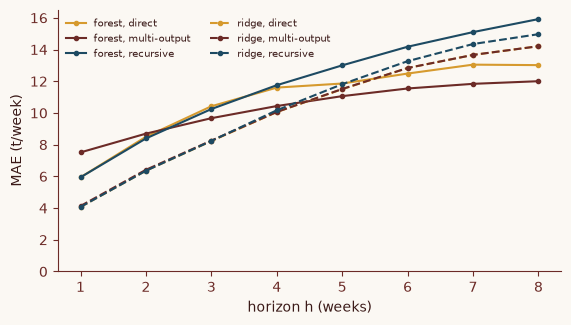

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for (model, s), row in mae_h.iterrows():
    ax.plot(row.index, row.values, color=COL[s], ls="-" if model == "forest" else "--", marker=".", label=f"{model}, {s}")
ax.set(xlabel="horizon h (weeks)", ylabel="MAE (t/week)", ylim=(0, None))
ax.legend(frameon=False, fontsize=7, ncol=2)
plt.show()

**Figure 1 | Error by horizon.** MAE over 96 origins, averaged over 8 synthetic histories. Solid: forests. Dashed: ridge.

The costs, per history:

In [9]:
wide = rows.pivot_table(index="seed", columns=["model", "strategy"], values="mae")
mo = wide["forest", "multi-output"]
print(f"multi-output forest has lower mean MAE than direct forest in {(mo < wide['forest', 'direct']).sum()} "
      f"of 8 histories, than recursive forest in {(mo < wide['forest', 'recursive']).sum()}")
rows.groupby(["model", "strategy"])[["jumpiness", "fit_s"]].mean().round(2)  # per history

multi-output forest has lower mean MAE than direct forest in 8 of 8 histories, than recursive forest in 7


jumpiness  fit_s
model  strategy                      
forest direct             3.55   4.68
       multi-output       1.02   0.63
       recursive          1.82   0.59
ridge  direct             1.71   0.04
       multi-output       1.68   0.01
       recursive          1.48   0.01

Among forests, the multi-output model is best from $h = 4$ ($10.4$ against $11.6$ direct and $11.8$ recursive) and on the mean ($10.3$ against $10.9$ and $11.8$), and beat the direct forests on mean MAE in all 8 histories and the recursive forest in 7. It fitted $4.68 / 0.63 = 7.4$ times faster than eight direct forests. The recursive forest degrades fastest, to $15.9$ at $h = 8$.

It loses at $h = 1$: MAE $7.5$ against $5.9$ for both other forests. The diagnostic forest, trained on the multi-output rows, scores $6.3$, so fewer rows cost $0.4$ and the shared fit $1.2$: the cost, here, of one tree structure and one set of hyperparameters for all horizons. A likely reason, untested: splits serving weeks 2 to 8 lean on last season's curve, while next week depends most on this week.

Direct and multi-output ridge agree, as the algebra predicts; recursive ridge trails only late, $15.0$ against $14.2$ at $h = 8$. Ridge beats every forest up to $h = 4$ and edges the best forest on the mean, $10.1$ against $10.3$; only at $h = 8$ does the multi-output forest pull clear, $12.0$ against $14.2$. Our inference: try a linear baseline before assuming trees win. The 7-fold speed-up and the $10.9 - 10.3 = 0.6$ t/week gain over direct forests come from one synthetic series without outside predictors such as weather: they show what to test, not what to expect.

## Smooth paths and totals that add up

**Jumpiness** measures how much a forecast path bends from week to week; a straight line scores zero. Smooth means easier to plan from, not more accurate: actual paths, noise and all, score $4.94$; the noise-free signal $1.05$. The multi-output forest scores $1.02$, about as smooth as the signal; the direct forests score $3.55$, $3.5$ times as jumpy, because each week comes from a different forest and nothing ties week 3 to weeks 2 and 4.

::: {.callout-note collapse="true"}
## Jumpiness, and why a multi-output forest averages whole paths

Jumpiness is the absolute second difference $|\hat y_{t+h+1 \mid t} - 2\hat y_{t+h \mid t} + \hat y_{t+h-1 \mid t}|$, averaged over $h = 2, \dots, H - 1$ and over origins (t/week).

A forest's forecast weights the training rows: row $i$ gets $w_i(\mathbf{x}) \ge 0$, its share of the leaves that the new input $\mathbf{x}$ lands in, and the weights sum to one. A multi-output forest uses one set of weights for every horizon:

$$\hat{\mathbf{y}}(\mathbf{x}) = \sum_i w_i(\mathbf{x})\, \mathbf{Y}_i$$

where $\mathbf{Y}_i$ is the observed $H$-week path of row $i$. A second difference is linear, so the forecast's bend is the weighted average of the training paths' bends, no larger in size than their average size. Any linear constraint that every training path meets, such as shares summing to one, holds for the forecast too. Direct forests use different weights for each horizon, so neither holds.
:::

To check that totals add up, add the 8-week total as a ninth target and compare it with the sum of the forecast weeks:

In [10]:
y0 = simulate(0)[0]
X, Y = table(y0, np.arange(P, 4 * P - H))  # history 0, four seasons of rows, every target observed
Y9 = np.c_[Y, Y.sum(axis=1)]  # the 8 weeks plus their 8-week total as a ninth target
x = np.array([features(y0, t) for t in range(4 * P, 5 * P)])  # every origin of season 5
for name, p in [("one multi-output forest", forest().fit(X, Y9).predict(x)),
                ("nine separate forests", np.column_stack([forest().fit(X, Y9[:, k]).predict(x) for k in range(H + 1)]))]:
    gap = np.abs(p[:, :H].sum(axis=1) - p[:, H])
    print(f"{name:24s} |total - sum of weeks|: mean {gap.mean():.2f} t, max {gap.max():.2f} t; "
          f"mean total {p[:, H].mean():.0f} t")

one multi-output forest  |total - sum of weeks|: mean 0.00 t, max 0.00 t; mean total 229 t
nine separate forests    |total - sum of weeks|: mean 14.84 t, max 82.89 t; mean total 227 t


One multi-output forest adds up exactly; nine separate forests miss by $14.84$ t on average and up to $82.89$ t, against a mean total of $229$ t. The same property keeps the forest's shares in [Compositional data](../compositional-data.qmd) summing to one; separately made forecasts need [Hierarchical reconciliation](../hierarchical-reconciliation/hierarchical_reconciliation.ipynb). The flip side: an average of seen paths cannot go beyond them.

::: {.callout-tip}
## What this means for you

Our inference from one synthetic series: backtest one multi-output forest against your per-horizon models, with a linear model and a separate next-week model in the same backtest.
:::

## Key takeaways

- Choose per horizon: a direct model for next week and a multi-output model for the rest is a legitimate forecast.
- A multi-output model loses $H - 1$ recent rows per refit; with short histories or long horizons, count them first.
- When weeks must add to a total, or shares to one, use a model that averages whole target rows or is linear in them, or reconcile.
- Report jumpiness beside MAE when planners use the shape of the path.

## References

[^1]: Ben Taieb, S., Bontempi, G., Atiya, A. F. & Sorjamaa, A. A review and comparison of strategies for multi-step ahead time series forecasting based on the NN5 forecasting competition. *Expert Syst. Appl.* **39**, 7067–7083 (2012). https://doi.org/10.1016/j.eswa.2012.01.039

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/darts-direct-vs-recursive.html"><span>Previous</span>Direct vs recursive in Darts</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/darts-size-distribution-forecast.html"><span>Next</span>Forecasting a size distribution</a></div>
<!-- CURRICULUM_FOOTER_END -->